
Random Forest Results:
Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2


MLP Neural Network Results:
Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2


Logistic Regression Results:
Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


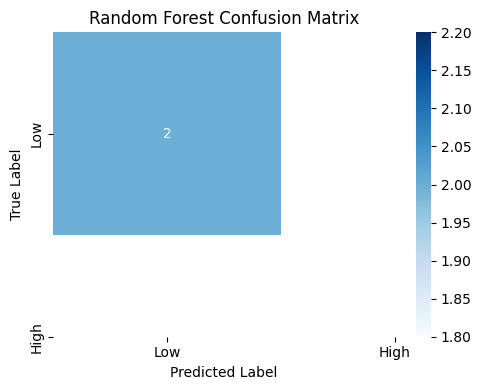

/tmp/ipython-input-1186024038.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feat_names, palette='magma')


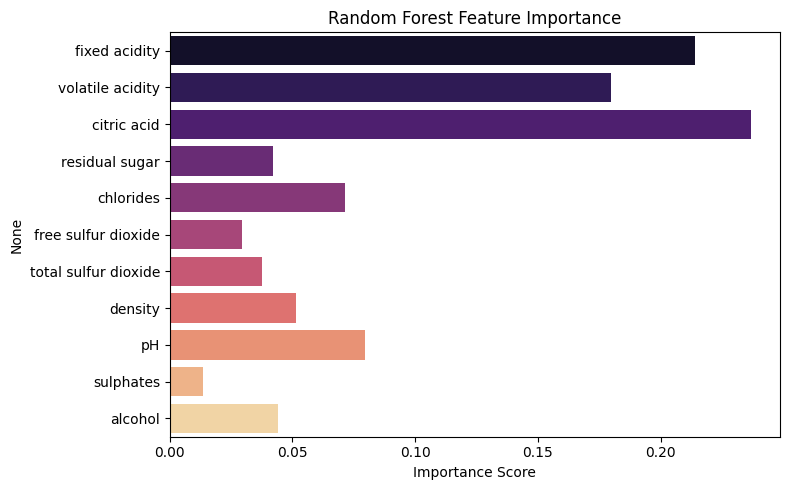


Predicted wine quality for new sample: Low


In [1]:
# Wine Quality Prediction using Machine Learning

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Sample data (real datasets have thousands of rows; use this for demonstration or code testing)
data = pd.DataFrame({
    'fixed acidity': [7.0, 7.4, 6.5, 7.8, 7.1, 6.3, 8.1, 7.5, 6.8, 7.0],
    'volatile acidity': [0.27, 0.70, 0.30, 0.66, 0.28, 0.35, 0.22, 0.29, 0.32, 0.26],
    'citric acid': [0.36, 0.00, 0.37, 0.04, 0.35, 0.37, 0.38, 0.27, 0.32, 0.37],
    'residual sugar': [20.7, 1.9, 6.1, 1.2, 8.0, 3.6, 6.9, 7.2, 7.0, 1.9],
    'chlorides': [0.045, 0.076, 0.045, 0.075, 0.045, 0.040, 0.052, 0.038, 0.041, 0.044],
    'free sulfur dioxide': [45, 11, 12, 30, 34, 13, 30, 29, 29, 20],
    'total sulfur dioxide': [170, 34, 67, 97, 132, 80, 97, 102, 98, 94],
    'density': [1.001, 0.9978, 0.994, 0.9994, 0.9967, 0.9958, 0.997, 0.9955, 0.9967, 0.9956],
    'pH': [3.00, 3.51, 3.24, 3.26, 3.19, 3.38, 3.21, 3.26, 3.36, 3.30],
    'sulphates': [0.45, 0.56, 0.49, 0.59, 0.40, 0.47, 0.45, 0.45, 0.44, 0.43],
    'alcohol': [8.8, 9.4, 10.2, 10.9, 10.5, 9.5, 10.5, 11.4, 9.8, 10.0],
    'quality': [6, 5, 6, 5, 6, 5, 7, 6, 5, 6]
})

# Preprocessing: convert quality to binary class ("good" = 1 if quality >= 7, else 0)
data['quality_label'] = data['quality'].apply(lambda x: 1 if x >= 7 else 0)
X = data.drop(['quality', 'quality_label'], axis=1)
y = data['quality_label']

# Feature scaling to improve ML model behavior
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split for model building
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Model definitions
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
mlp_model = MLPClassifier(hidden_layer_sizes=(50,50), max_iter=500, random_state=42)
log_model = LogisticRegression(max_iter=200, random_state=42)

# Train models
rf_model.fit(X_train, y_train)
mlp_model.fit(X_train, y_train)
log_model.fit(X_train, y_train)

# Predict on test set
rf_pred = rf_model.predict(X_test)
mlp_pred = mlp_model.predict(X_test)
log_pred = log_model.predict(X_test)

# Evaluation metrics table
def print_model_results(name, y_true, y_pred):
    print(f"\n{name} Results:")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.2f}")
    print(classification_report(y_true, y_pred))

print_model_results("Random Forest", y_test, rf_pred)
print_model_results("MLP Neural Network", y_test, mlp_pred)
print_model_results("Logistic Regression", y_test, log_pred)

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# Feature Importance Visualization for Random Forest
importances = rf_model.feature_importances_
feat_names = X.columns
plt.figure(figsize=(8,5))
sns.barplot(x=importances, y=feat_names, palette='magma')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Prediction demo for new sample inputs
new_sample = pd.DataFrame([{
    'fixed acidity': 7.5,
    'volatile acidity': 0.30,
    'citric acid': 0.36,
    'residual sugar': 8.1,
    'chlorides': 0.043,
    'free sulfur dioxide': 28,
    'total sulfur dioxide': 95,
    'density': 0.9968,
    'pH': 3.28,
    'sulphates': 0.46,
    'alcohol': 10.2
}])
scaled_sample = scaler.transform(new_sample)
pred_quality = rf_model.predict(scaled_sample)[0]
print(f"\nPredicted wine quality for new sample: {'High' if pred_quality == 1 else 'Low'}")

